# View the battery dataset

Run the cells from top to bottom using **Shift+Enter**. In VS Code, select a Python kernel first.

Start with **RW26.mat**, the smallest battery file. This notebook loads **one complete battery** into memory, then shows compact previews. Selecting a step does not reduce the amount initially loaded. Files can occupy substantially more RAM than their size on disk.

A **step** is an experimental segment (such as charge, discharge, or rest), not necessarily a complete battery cycle. This notebook is for viewing and initial inspection before full EDA.

## 1. Imports

If the next cell reports a missing package, uncomment and run the installation cell below, then rerun the imports. Installation uses the active notebook kernel.

In [ ]:
# Uncomment only if needed:
# %pip install scipy numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat, whosmat
from IPython.display import display

pd.set_option("display.max_colwidth", 70)

## 2. Find the dataset and preview file sizes

The notebook locates the project by looking for a `dataset` directory in the current working directory or its parents. If you launch it elsewhere, set `PROJECT_ROOT` to the folder containing this notebook. This cell reads file sizes only; it does not load the measurements.

In [3]:
PROJECT_ROOT = None  # Example: Path(r"C:\Users\Admin\code\eda_asm\batterylife")

if PROJECT_ROOT is None:
    root = next(
        (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dataset").is_dir()),
        None,
    )
    if root is None:
        raise FileNotFoundError("Set PROJECT_ROOT to the project folder containing dataset.")
else:
    root = Path(PROJECT_ROOT).expanduser().resolve()

files = sorted((root / "dataset").rglob("*.mat"))
if not files:
    raise FileNotFoundError(f"No .mat files found under {root / 'dataset'}")

inventory = pd.DataFrame([
    {
        "battery": p.stem,
        "size_MiB": p.stat().st_size / 1024**2,
        "relative_path": str(p.relative_to(root)),
    }
    for p in files
]).sort_values("size_MiB").reset_index(drop=True)

print(f"Project: {root}")
print(f"{len(files)} files; {inventory['size_MiB'].sum():.1f} MiB total on disk")
display(inventory.round({"size_MiB": 2}))

Project: c:\Users\Admin\code\eda_asm\batterylife
28 files; 776.6 MiB total on disk


,battery,size_MiB,relative_path
0,RW26,9.30,dataset\dataset\RW_Skewed_High_40C_DataSet_2Post\RW_Skewed_High_40...
1,RW28,10.64,dataset\dataset\RW_Skewed_High_40C_DataSet_2Post\RW_Skewed_High_40...
2,RW25,10.67,dataset\dataset\RW_Skewed_High_40C_DataSet_2Post\RW_Skewed_High_40...
3,RW27,11.59,dataset\dataset\RW_Skewed_High_40C_DataSet_2Post\RW_Skewed_High_40...
4,RW6,15.56,dataset\dataset\Battery_Uniform_Distribution_Discharge_Room_Temp_D...
5,RW20,15.61,dataset\dataset\RW_Skewed_High_Room_Temp_DataSet_2Post\RW_Skewed_H...
6,RW22,16.01,dataset\dataset\RW_Skewed_Low_40C_DataSet_2Post\RW_Skewed_Low_40C_...
7,RW17,16.08,dataset\dataset\RW_Skewed_High_Room_Temp_DataSet_2Post\RW_Skewed_H...
8,RW18,16.12,dataset\dataset\RW_Skewed_High_Room_Temp_DataSet_2Post\RW_Skewed_H...
9,RW24,16.29,dataset\dataset\RW_Skewed_Low_40C_DataSet_2Post\RW_Skewed_Low_40C_...


## 3. Select and load one battery

Change `BATTERY_FILE` to another filename from the inventory when ready. The default is `RW26.mat` (about 9.3 MiB on disk).

**When switching batteries:** restart the kernel, change the filename, and run the notebook from the top. This releases old battery data and avoids confusing an old preview with a new selection.

`whosmat` inspects top-level variables before loading. `loadmat` then reads the complete `data` structure. These files use the older MATLAB format supported by SciPy; this is not an HDF5 chunked reader.

In [4]:
BATTERY_FILE = "RW26.mat"

matches = [p for p in files if p.name.lower() == BATTERY_FILE.lower()]
if len(matches) != 1:
    raise ValueError(f"Expected one match for {BATTERY_FILE}, found {len(matches)}. Check inventory.")
path = matches[0]

print(f"Selected: {path.name} ({path.stat().st_size / 1024**2:.1f} MiB)")
print("Top-level variables:", whosmat(path))

data = loadmat(path, variable_names=["data"], simplify_cells=True)["data"]
steps = data["step"]
if isinstance(steps, dict):  # Also support a file containing just one step.
    steps = [steps]

print("Data fields:", list(data))
print(f"Number of steps: {len(steps):,}")
print("Description:", data.get("description", "Not provided"))
if len(steps):
    print("Step fields:", list(steps[0]))

Selected: RW26.mat (9.3 MiB)
Top-level variables: [('data', (1, 1), 'struct')]
Data fields: ['step', 'procedure', 'description']
Number of steps: 16,666
Description: Experiment consisting of repeated iteration of a randomized series of discharging pulses that are selected form a custom distribution. The custom distribution runs from 0.5A to 4A and is skewed towards the higher end of that range. After the battery discharging threshold is reached it is recharged to 4.2V. Batteries are charged and discharged at 40 degrees C
Step fields: ['comment', 'type', 'time', 'relativeTime', 'voltage', 'current', 'temperature', 'date']


## 4. Browse the experiment steps

This table contains one row per step, without expanding its measurement arrays. `step_index` is **zero-based**: index `0` is the first MATLAB step.

The activity counts help identify reference discharges, random-walk segments, charging, and rest periods.

In [5]:
summary = pd.DataFrame([
    {
        "step_index": i,
        "activity": s.get("comment", ""),
        "type": s.get("type", ""),
        "date": s.get("date", ""),
        "samples": np.size(s["voltage"]),
    }
    for i, s in enumerate(steps)
])

display(summary.head(20))
display(summary["activity"].value_counts().rename_axis("activity").to_frame("step_count"))

,step_index,activity,type,date,samples
0,0,charge (after random walk discharge),C,14-Nov-2014 17:25:43,164
1,1,rest prior reference discharge,R,14-Nov-2014 20:08:30,6
2,2,reference discharge,D,14-Nov-2014 20:13:31,259
3,3,rest post reference discharge,R,14-Nov-2014 22:22:21,91
4,4,reference charge,C,14-Nov-2014 23:52:22,184
5,5,rest post reference charge,R,15-Nov-2014 02:54:43,6
6,6,reference power discharge,D,15-Nov-2014 02:59:44,310
7,7,rest post reference power discharge,R,15-Nov-2014 03:10:01,91
8,8,pulsed load (rest),R,15-Nov-2014 06:49:11,121
9,9,pulsed load (discharge),D,15-Nov-2014 07:09:11,601


,step_count
activity,
rest (random walk),7447
discharge (random walk),7447
charge (after random walk discharge),664
rest post random walk discharge,650
pulsed load (rest),173
pulsed load (discharge),173
rest prior reference discharge,14
reference discharge,14
rest post reference discharge,14


## 5. Find reference discharge steps

These segments are useful for later comparisons of discharge behavior. This cell lists available indices; it does not change the selected step.

In [6]:
reference_steps = summary.loc[summary["activity"].eq("reference discharge")]
print(f"Reference discharge steps: {len(reference_steps)}")
display(reference_steps.head(20))
if not reference_steps.empty:
    print("First reference discharge step_index:", int(reference_steps.iloc[0]["step_index"]))

Reference discharge steps: 14


,step_index,activity,type,date,samples
2,2,reference discharge,D,14-Nov-2014 20:13:31,259
2043,2043,reference discharge,D,23-Nov-2014 02:07:07,251
3850,3850,reference discharge,D,01-Dec-2014 05:31:34,247
5485,5485,reference discharge,D,09-Dec-2014 06:52:41,243
6920,6920,reference discharge,D,17-Dec-2014 03:02:16,240
8205,8205,reference discharge,D,24-Dec-2014 17:08:12,237
9364,9364,reference discharge,D,01-Jan-2015 03:35:52,234
10469,10469,reference discharge,D,08-Jan-2015 13:04:11,232
11578,11578,reference discharge,D,15-Jan-2015 22:40:07,229
12631,12631,reference discharge,D,23-Jan-2015 07:14:15,228


First reference discharge step_index: 2


## 6. View measurements in a selected step

Set `STEP_INDEX` to any index from the tables above. To inspect the first reference discharge, use the commented assignment instead. Rerun this cell and the plotting cell after changing the index.

Each row below is one measurement within the selected step. `relative_time_s` is time within the step, in seconds. Current values retain the source sign; do not assume all current is positive.

In [7]:
STEP_INDEX = 0
# STEP_INDEX = int(reference_steps.iloc[0]["step_index"])  # If reference_steps is nonempty

if not isinstance(STEP_INDEX, (int, np.integer)) or not 0 <= STEP_INDEX < len(steps):
    raise ValueError(f"STEP_INDEX must be an integer from 0 to {len(steps) - 1}.")

step = steps[STEP_INDEX]
columns = {
    "relative_time_s": np.atleast_1d(step["relativeTime"]).ravel(),
    "voltage_V": np.atleast_1d(step["voltage"]).ravel(),
    "current_A": np.atleast_1d(step["current"]).ravel(),
    "temperature_C": np.atleast_1d(step["temperature"]).ravel(),
}
lengths = {name: values.size for name, values in columns.items()}
if len(set(lengths.values())) != 1:
    raise ValueError(f"Measurement lengths differ in step {STEP_INDEX}: {lengths}")

measurements = pd.DataFrame(columns)
print(f"{path.stem} | step {STEP_INDEX} | {step.get('comment', '')}")
print(f"Date: {step.get('date', '')} | {len(measurements):,} measurements")
display(measurements.head(20))
display(measurements.describe())
display(measurements.isna().sum().to_frame("missing_values"))

RW26 | step 0 | charge (after random walk discharge)
Date: 14-Nov-2014 17:25:43 | 164 measurements


,relative_time_s,voltage_V,current_A,temperature_C
0,0.04,4.023,-2.005,35.32811
1,60.04,4.080,-2.000,35.75813
2,120.04,4.090,-2.000,36.46461
3,180.04,4.096,-2.000,37.01750
4,240.04,4.101,-2.000,37.57039
5,300.04,4.107,-2.000,38.09256
6,360.04,4.113,-2.000,38.59938
7,420.04,4.119,-2.000,39.06013
8,480.04,4.124,-2.000,39.53623
9,540.04,4.129,-2.000,39.93554


,relative_time_s,voltage_V,current_A,temperature_C
count,164.000000,164.000000,164.000000,164.000000
mean,4889.960427,4.191537,-0.567921,39.310166
std,2849.073189,0.026855,0.713261,1.627684
min,0.040000,4.023000,-2.005000,35.328110
25%,2445.040000,4.200000,-0.920750,38.338290
50%,4890.040000,4.200000,-0.175500,38.399730
75%,7335.040000,4.200000,-0.041500,40.019897
max,9766.990000,4.200000,-0.010000,43.099510


,missing_values
relative_time_s,0
voltage_V,0
current_A,0
temperature_C,0


## 7. Plot the selected step

The three panels use separate vertical axes because voltage, current, and temperature have different units. Only this step is plotted.

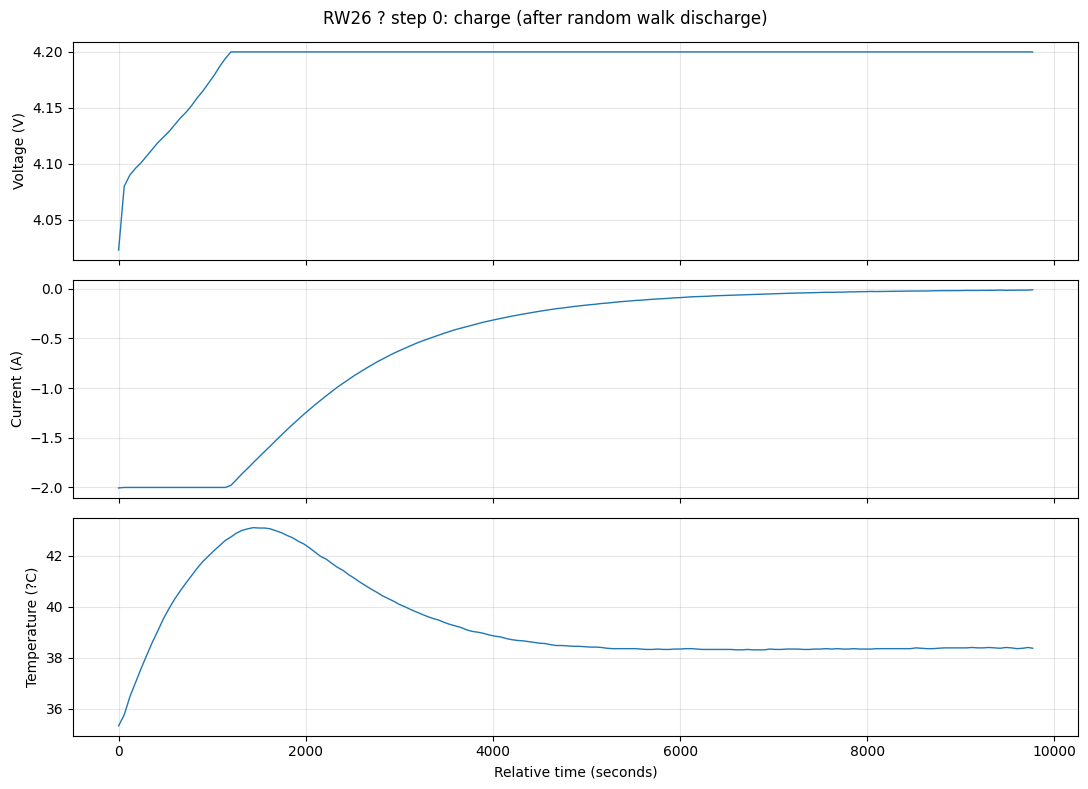

In [8]:
plt.close("all")
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

for ax, column, label in zip(
    axes,
    ["voltage_V", "current_A", "temperature_C"],
    ["Voltage (V)", "Current (A)", "Temperature (?C)"],
):
    ax.plot(measurements["relative_time_s"], measurements[column], linewidth=1)
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Relative time (seconds)")
fig.suptitle(f"{path.stem} ? step {STEP_INDEX}: {step.get('comment', '')}")
fig.tight_layout()
plt.show()

## Before full EDA

- Inspect several activities and reference discharge steps to understand the experiment structure.
- Keep previews bounded with `.head(20)`; avoid displaying `data` or `steps` in full.
- Restart the kernel before switching batteries if memory is tight. Do not combine all raw measurements yet.
- Later EDA can compare reference discharge curves, sampling intervals, missing values, and battery degradation. Capacity estimation and cycle grouping require additional analysis.

Loading reference: [SciPy loadmat documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.loadmat.html).